# 05 · Suelos, tabla maestra, pliegues de validación y referencias oficiales — Reto AgroCebada 2026

## Qué hace este cuaderno
Añade el último bloque de información, el **suelo**, y luego prepara todo lo que necesitan los modelos: una **tabla maestra** con todas las variables de las 197 parcelas, un conjunto fijo de **pliegues de validación** en el que se evaluará cada modelo, la **referencia oficial** que todo modelo debe superar y un **mapa de variables redundantes** para que los modelos no cuenten dos veces la misma información.

## Por qué el suelo
Los píxeles de clima miden 5 km, así que parcelas vecinas comparten la misma lluvia. El suelo cambia en cientos de metros: una parcela arenosa drena y se seca rápido, una arcillosa retiene agua durante un periodo seco y la materia orgánica nutre al cultivo. SoilGrids (ISRIC) mapea propiedades del suelo en todo el mundo a **250 m** a partir de ~240,000 perfiles y covariables, así que puede distinguir parcelas vecinas. Sus valores son *predicciones* con incertidumbre, no mediciones: sirven como diferencias relativas entre parcelas.

## Por qué fijar ahora los pliegues de validación
Todos los modelos de los cuadernos 06 y 07 se evaluarán en **exactamente las mismas** particiones de las 138 parcelas de entrenamiento. Comparar modelos en particiones distintas mezcla diferencias reales con suerte. Fijar las particiones una sola vez, antes de que exista cualquier modelo, también evita elegir sin querer particiones que favorezcan a un modelo.

## Pasos
| Paso | Qué |
|---|---|
| A | Suelo: descargar SoilGrids (en caché en Drive), convertir unidades, promedios exactos por polígono para 0–30 cm y capacidad de retención de agua (Saxton y Rawls, 2006) |
| B | Armonizar y unir todas las tablas de variables en `features/master.parquet`; catálogo combinado de variables |
| C | Pliegues fijos de validación: 10 repeticiones de validación cruzada estratificada de 5 pliegues (principal) y bloques espaciales (secundario) |
| D | Referencias oficiales de ubicación en esos pliegues: la métrica a superar |
| E | Mapa de redundancia: grupos de variables casi duplicadas (sin usar el rendimiento) |
| F | Mirada descriptiva a todos los grupos de variables; reporte; `docs/sources.md` |

## Entradas
`interim/plots.parquet`, `interim/labels.parquet`, `features/sat_features.parquet`, `features/climate_features.parquet`, `features/topo_features.parquet` y los tres catálogos de variables.

## Salidas
| Archivo | Contenido |
|---|---|
| `raw_external/soilgrids/*.tif` | mosaicos de SoilGrids descargados (caché; si se vuelve a correr no se descargan de nuevo) |
| `features/soil_features.parquet` | variables de suelo por parcela |
| `features/master.parquet` | una fila por parcela: identificadores, ubicación, conjunto, rendimiento (solo entrenamiento) y todas las variables |
| `features/feature_catalog_all.csv` | cada variable con grupo, fuente, unidad, descripción, `use_in_model` y grupo de redundancia |
| `models/cv_folds.json`, `models/cv_spatial.json` | los pliegues fijos de validación |
| `models/baselines_cv.json` | métricas oficiales de las referencias en los pliegues |
| `docs/sources.md` | cada fuente de datos y referencia de método |
| `qa/nb05_*`, `qa/figures/nb05_*`, `qa/nb05_report.md` | verificaciones, figuras y reporte |

**Tiempo de ejecución:** 2–5 minutos (más la descarga del suelo la primera vez, normalmente menos de 2 minutos).

## 0 · Preparación

In [1]:
!pip install -q rasterio owslib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 241.3/241.3 kB 5.8 MB/s eta 0:00:00


In [2]:
# 0.1 · Librerías, Drive y rutas
import os, re, io, json, math, time, warnings
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

BASE = Path("/content/drive/MyDrive/AgroCebada") if IN_COLAB else Path(os.environ.get("AGC_BASE", "AgroCebada"))
INTERIM, FEATURES, MODELS, QA, DOCS = BASE / "interim", BASE / "features", BASE / "models", BASE / "qa", BASE / "docs"
SOILDIR = BASE / "raw_external" / "soilgrids"
FIG = QA / "figures"
for d in [FEATURES, MODELS, FIG, DOCS, SOILDIR]:
    d.mkdir(parents=True, exist_ok=True)
for f in ["sat_features.parquet", "climate_features.parquet", "topo_features.parquet", "feature_catalog.csv", "feature_catalog_nb04.csv"]:
    assert (FEATURES / f).exists(), f"Falta features/{f}: ejecuta primero los cuadernos 03 y 04."

SEED = 42
RNG = np.random.default_rng(SEED)
if "display" not in globals():
    display = print
print(f"BASE = {BASE} | Colab: {IN_COLAB}")

Mounted at /content/drive
BASE = /content/drive/MyDrive/AgroCebada | Colab: True


In [3]:
# 0.2 · Configuración fija
SOIL_PROPS = {   # propiedad de SoilGrids v2.0: (factor de conversión a la unidad de la derecha, unidad, rango plausible tras convertir, significado)
    "clay":     (0.1,  "%",          (0, 80),  "contenido de arcilla (< 0.002 mm)"),
    "sand":     (0.1,  "%",          (0, 95),  "contenido de arena (0.05–2 mm)"),
    "silt":     (0.1,  "%",          (0, 80),  "contenido de limo (0.002–0.05 mm)"),
    "soc":      (0.1,  "g/kg",       (0, 200), "carbono orgánico del suelo"),
    "nitrogen": (0.01, "g/kg",       (0, 20),  "nitrógeno total"),
    "bdod":     (0.01, "kg/dm³",     (0.5, 2), "densidad aparente de la tierra fina"),
    "phh2o":    (0.1,  "pH",         (3.5, 10), "pH en agua"),
    "cec":      (0.1,  "cmol(c)/kg", (0, 100), "capacidad de intercambio catiónico (capacidad de retener nutrientes)"),
    "cfvo":     (0.1,  "% vol",      (0, 90),  "fragmentos gruesos (piedras > 2 mm)"),
}
DEPTHS = {"0-5cm": 5, "5-15cm": 10, "15-30cm": 15}       # capa superficial 0–30 cm, ponderada por el espesor de cada capa
SOIL_RES = 0.0025                                       # ≈ 270 m en grados (SoilGrids nativo de 250 m)
BBOX_PAD = 0.02                                         # grados alrededor de las parcelas
WCS_URL = "https://maps.isric.org/mapserv?map=/map/{prop}.map"
REST_URL = "https://rest.isric.org/soilgrids/v2.0/properties/query"
NODATA_FLOOR = -1000

MUNI_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
GROUP_COLORS = {"phenology": "#2a78d6", "window": "#86b6ef", "uniformity": "#4a3aa7", "history": "#1c5cab",
                "climate": "#eb6834", "climate anomaly": "#f2a07b", "terrain": "#1baf7a", "soil": "#eda100", "plot": "#9a9a94"}
GREY, RED, INK = "#9a9a94", "#e34948", "#2b2b28"
# nombres en español de los grupos para las figuras (los identificadores internos no cambian)
GRUPOS = {"phenology": "fenología", "window": "ventanas", "uniformity": "uniformidad", "history": "historial",
          "climate": "clima", "climate anomaly": "anomalía climática", "terrain": "terreno", "soil": "suelo", "plot": "parcela"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#b8b7ae", "axes.labelcolor": INK, "xtick.color": "#6b6b66",
                     "ytick.color": "#6b6b66", "font.size": 9, "legend.frameon": False})

CHECKS, CATALOG = [], []
def check(name, ok, detail="", warn_only=True, info=False):
    status = "INFO" if info else ("PASS" if ok else ("WARN" if warn_only else "FAIL"))
    rec = {"check": name, "status": status, "detail": str(detail)}
    for j, r in enumerate(CHECKS):
        if r["check"] == name:
            CHECKS[j] = rec
            break
    else:
        CHECKS.append(rec)
    print(f"[{status}] {name}" + (f" — {detail}" if detail != "" else ""))

def register(name, group, source, var, window, stat, description, unit="", use=True):
    CATALOG.append(dict(feature=name, group=group, sensor=source, index=var, window=window, statistic=stat,
                        unit=unit, description=description, use_in_model=use))

In [4]:
# 0.3 · Parcelas y rendimientos
import geopandas as gpd
import rasterio

plots = gpd.read_parquet(INTERIM / "plots.parquet").sort_values("ID_POLIGONO").reset_index(drop=True)
IDS = plots.ID_POLIGONO.tolist()

def rings_of(geom):
    polys = [geom] if geom.geom_type == "Polygon" else list(geom.geoms)
    return [([tuple(c[:2]) for c in p.exterior.coords[:-1]], [[tuple(c[:2]) for c in h.coords[:-1]] for h in p.interiors])
            for p in polys]
RINGS_GEO = [rings_of(g) for g in plots.geometry]
LONLAT = plots[["lon", "lat"]].to_numpy()
b = plots.total_bounds
BBOX = (b[0] - BBOX_PAD, b[1] - BBOX_PAD, b[2] + BBOX_PAD, b[3] + BBOX_PAD)

def read_tif(path):
    with rasterio.open(path) as src:
        a = np.ma.filled(src.read(1, masked=True).astype("float64"), np.nan)
        T = src.transform
        a[a < NODATA_FLOOR] = np.nan
        return a, (T.a, T.c, T.e, T.f), src.crs.to_epsg()

attrs = pd.DataFrame(plots.drop(columns="geometry"))
labels = pd.read_parquet(INTERIM / "labels.parquet")
print(f"{len(IDS)} parcelas; rectángulo para el suelo (lon/lat): {tuple(round(x, 3) for x in BBOX)}")

197 parcelas; rectángulo para el suelo (lon/lat): (np.float64(-98.633), np.float64(19.504), np.float64(-98.177), np.float64(20.004))


In [5]:
# 0.4 · Extracción exacta ponderada por área (idéntica al cuaderno 04)
def _clip(pts, axis, bound, keep_ge):
    out, n = [], len(pts)
    for i in range(n):
        P, Q = pts[i], pts[(i + 1) % n]
        pin = P[axis] >= bound if keep_ge else P[axis] <= bound
        qin = Q[axis] >= bound if keep_ge else Q[axis] <= bound
        if pin:
            out.append(P)
        if pin != qin:
            t = (bound - P[axis]) / (Q[axis] - P[axis])
            out.append((P[0] + t * (Q[0] - P[0]), P[1] + t * (Q[1] - P[1])))
    return out

def _area(pts):
    if len(pts) < 3:
        return 0.0
    s = 0.0
    for i in range(len(pts)):
        (x1, y1), (x2, y2) = pts[i], pts[(i + 1) % len(pts)]
        s += x1 * y2 - x2 * y1
    return abs(s) / 2

def _ring_in_box(ring, xmin, ymin, xmax, ymax):
    pts = ring
    for axis, b, ge in ((0, xmin, True), (0, xmax, False), (1, ymin, True), (1, ymax, False)):
        pts = _clip(pts, axis, b, ge)
        if not pts:
            return 0.0
    return _area(pts)

def coverage(parts, grid, width, height):
    """Píxeles que toca un polígono y la fracción de su área en cada uno. grid = (a, c, e, f): x = c + col·a, y = f + fila·e."""
    a, c, e, f = grid
    total = sum(_area(ext) - sum(_area(h) for h in holes) for ext, holes in parts)
    xs = [p[0] for ext, _ in parts for p in ext]
    ys = [p[1] for ext, _ in parts for p in ext]
    c0, c1 = max(int(math.floor((min(xs) - c) / a)), 0), min(int(math.floor((max(xs) - c) / a)), width - 1)
    r0, r1 = max(int(math.floor((max(ys) - f) / e)), 0), min(int(math.floor((min(ys) - f) / e)), height - 1)
    R, Cl, W = [], [], []
    for r in range(r0, r1 + 1):
        ymax = f + r * e
        ymin = ymax + e
        for col in range(c0, c1 + 1):
            xmin = c + col * a
            A = sum(_ring_in_box(ext, xmin, ymin, xmin + a, ymax) - sum(_ring_in_box(h, xmin, ymin, xmin + a, ymax) for h in holes)
                    for ext, holes in parts)
            if A > 0:
                R.append(r); Cl.append(col); W.append(A / total)
    return np.array(R, int), np.array(Cl, int), np.array(W, float)

def weighted(arr, cov):
    """Media ponderada por área sobre los píxeles válidos y fracción válida de la parcela."""
    R, Cl, W = cov
    v = arr[R, Cl]
    ok = np.isfinite(v)
    share = W[ok].sum()
    return (float((W[ok] * v[ok]).sum() / share) if share > 0 else np.nan), float(share)

## 1 · Paso A: suelo de SoilGrids a 250 m

**Qué tomamos** (capa superficial de 0–30 cm, donde la cebada tiene la mayor parte de sus raíces): arcilla, arena, limo, carbono orgánico, nitrógeno, densidad aparente, pH, capacidad de intercambio catiónico (cuántos nutrientes puede retener el suelo) y fragmentos gruesos (piedras). Las tres capas de profundidad (0–5, 5–15 y 15–30 cm) se promedian usando su espesor (5, 10 y 15 cm) como peso.

**Cómo se descarga.** SoilGrids se sirve mediante un servicio de mapas estándar (WCS). Para cada propiedad y profundidad pedimos un GeoTIFF pequeño que cubre el área de las parcelas. Los archivos se guardan en `raw_external/soilgrids/`, así que la descarga solo ocurre una vez. Si el servicio de mapas falla, el cuaderno intenta una petición HTTP simple del mismo mosaico y, como último recurso, consulta el servicio puntual de SoilGrids en el centro de cada parcela (más lento: unos 30–40 minutos, porque el servicio solo permite pocas peticiones por minuto).

**Unidades.** SoilGrids guarda enteros; cada propiedad se convierte con su factor documentado (por ejemplo, arcilla en g/kg ÷ 10 → %, pH × 10 ÷ 10 → pH). Cada valor convertido se compara con un rango plausible.

**Capacidad de retención de agua.** La cantidad de agua que un suelo puede almacenar para la planta (entre capacidad de campo y punto de marchitez) se estima con las ecuaciones de **Saxton y Rawls (2006)** a partir de arena, arcilla y materia orgánica (materia orgánica = carbono orgánico × 1.724) y se expresa en mm para la capa de 0–30 cm. Es la variable de suelo más directamente ligada a la tolerancia a la sequía.

In [6]:
# 1.1 · Descarga (con caché): servicio de mapas y, si falla, HTTP simple
def tile_path(prop, depth):
    return SOILDIR / f"{prop}_{depth}_mean.tif"

def valid_tif(path):
    try:
        a, _, epsg = read_tif(path)
        return epsg == 4326 and np.isfinite(a).mean() > 0.5
    except Exception:
        return False

def fetch_owslib(prop, depth):
    from owslib.wcs import WebCoverageService
    wcs = WebCoverageService(WCS_URL.format(prop=prop), version="1.0.0")
    r = wcs.getCoverage(identifier=f"{prop}_{depth}_mean", crs="urn:ogc:def:crs:EPSG::4326", bbox=BBOX,
                        resx=SOIL_RES, resy=SOIL_RES, format="GEOTIFF_INT16")
    return r.read()

def fetch_http(prop, depth):
    import requests
    params = {"SERVICE": "WCS", "VERSION": "1.0.0", "REQUEST": "GetCoverage", "COVERAGE": f"{prop}_{depth}_mean",
              "CRS": "EPSG:4326", "BBOX": ",".join(f"{x:.5f}" for x in BBOX), "RESX": SOIL_RES, "RESY": SOIL_RES,
              "FORMAT": "GEOTIFF_INT16"}
    r = requests.get(WCS_URL.format(prop=prop), params=params, timeout=120)
    r.raise_for_status()
    return r.content

download_log = []
for prop in SOIL_PROPS:
    for depth in DEPTHS:
        p = tile_path(prop, depth)
        if p.exists() and valid_tif(p):
            download_log.append((prop, depth, "cached"))
            continue
        status = "failed"
        for name, fn in [("wcs", fetch_owslib), ("http", fetch_http)]:
            try:
                p.write_bytes(fn(prop, depth))
                if valid_tif(p):
                    status = name
                    break
            except Exception as e:
                status = f"failed ({type(e).__name__})"
            time.sleep(1)
        download_log.append((prop, depth, status))
dl = pd.DataFrame(download_log, columns=["property", "depth", "status"])
display(dl.pivot(index="property", columns="depth", values="status"))
TILES_OK = bool(dl.status.isin(["cached", "wcs", "http"]).all())
check("Mosaicos de SoilGrids disponibles para cada propiedad y profundidad", TILES_OK,
      dl.status.value_counts().to_dict() if TILES_OK else f"faltan: {dl[~dl.status.isin(['cached', 'wcs', 'http'])][['property', 'depth']].values.tolist()[:6]}; la siguiente celda recurre al servicio puntual")

depth      0-5cm 15-30cm  5-15cm
property                        
bdod      cached  cached  cached
cec       cached  cached  cached
cfvo      cached  cached  cached
clay      cached  cached  cached
nitrogen  cached  cached  cached
phh2o     cached  cached  cached
sand      cached  cached  cached
silt      cached  cached  cached
soc       cached  cached  cached
[PASS] Mosaicos de SoilGrids disponibles para cada propiedad y profundidad — {'cached': 27}


In [7]:
# 1.2 · Último recurso: servicio puntual de SoilGrids en el centro de cada parcela (lento; solo si fallaron los mosaicos)
POINT_SOIL = None
if not TILES_OK:
    import requests
    cache = SOILDIR / "rest_points.json"
    done = json.loads(cache.read_text()) if cache.exists() else {}
    print(f"Servicio puntual: {len(IDS) - len(done)} parcelas por consultar (≈ 12 s cada una; se puede reanudar si se interrumpe)")
    for pid, (lon, lat) in zip(IDS, LONLAT):
        if pid in done:
            continue
        params = [("lon", round(lon, 5)), ("lat", round(lat, 5)), ("value", "mean")] + \
                 [("property", p) for p in SOIL_PROPS] + [("depth", d) for d in DEPTHS]
        for attempt in range(4):
            try:
                r = requests.get(REST_URL, params=params, timeout=60)
                if r.status_code == 429:
                    time.sleep(30); continue
                r.raise_for_status()
                vals = {}
                for layer in r.json()["properties"]["layers"]:
                    for dd in layer["depths"]:
                        vals[f"{layer['name']}_{dd['label']}"] = dd["values"]["mean"]
                done[pid] = vals
                cache.write_text(json.dumps(done))
                break
            except Exception as e:
                time.sleep(15)
        time.sleep(12)
    POINT_SOIL = pd.DataFrame(done).T.reindex(IDS)
    check("Respaldo con el servicio puntual de SoilGrids", POINT_SOIL.notna().mean().mean() > 0.95,
          f"{int(POINT_SOIL.notna().all(axis=1).sum())} / {len(IDS)} parcelas completas (valores en el centro de la parcela, no promedios por polígono)")
else:
    print("Mosaicos disponibles: no se necesita el servicio puntual.")

Mosaicos disponibles: no se necesita el servicio puntual.


In [8]:
# 1.3 · Promedios por polígono, conversión de unidades, ponderación por profundidad y capacidad de retención de agua
SOIL = pd.DataFrame(index=pd.Index(IDS, name="ID_POLIGONO"))
layer_vals, valid_min = {}, []
if TILES_OK:
    cov_cache = {}
    for prop in SOIL_PROPS:
        for depth in DEPTHS:
            a, grid, epsg = read_tif(tile_path(prop, depth))
            key = tuple(round(x, 9) for x in grid) + a.shape
            if key not in cov_cache:
                cov_cache[key] = [coverage(r, grid, a.shape[1], a.shape[0]) for r in RINGS_GEO]
            v = [weighted(a, cov) for cov in cov_cache[key]]
            layer_vals[(prop, depth)] = np.array([x[0] for x in v])
            valid_min.append(min(x[1] for x in v))
    SOIL_METHOD = "promedio por polígono ponderado por área de los mosaicos de SoilGrids"
else:
    for prop in SOIL_PROPS:
        for depth in DEPTHS:
            layer_vals[(prop, depth)] = pd.to_numeric(POINT_SOIL.get(f"{prop}_{depth}"), errors="coerce").to_numpy(dtype=float)
    SOIL_METHOD = "servicio puntual de SoilGrids en el centro de cada parcela"

rng_rows = []
tot = sum(DEPTHS.values())
for prop, (factor, unit, (lo, hi), meaning) in SOIL_PROPS.items():
    layers = np.vstack([layer_vals[(prop, d)] * factor for d in DEPTHS])
    SOIL[f"soil_{prop}_0_30"] = np.nansum(layers * np.array(list(DEPTHS.values()))[:, None], axis=0) / tot
    SOIL.loc[np.isnan(layers).all(axis=0), f"soil_{prop}_0_30"] = np.nan
    SOIL[f"soil_{prop}_0_5"] = layers[0]
    register(f"soil_{prop}_0_30", "soil", "SoilGrids 2.0", prop, "0–30 cm", "thickness-weighted mean", f"{meaning}, capa superficial 0–30 cm", unit)
    register(f"soil_{prop}_0_5", "soil", "SoilGrids 2.0", prop, "0–5 cm", "mean", f"{meaning}, superficie 0–5 cm", unit)
    v = SOIL[f"soil_{prop}_0_30"]
    rng_rows.append({"property": prop, "unit": unit, "min": v.min(), "median": v.median(), "max": v.max(),
                     "plausible": f"{lo}–{hi}", "ok": bool(v.dropna().between(lo, hi).all())})
ranges = pd.DataFrame(rng_rows)
display(ranges.round(2))
check("Valores de suelo dentro de rangos plausibles tras convertir unidades", bool(ranges.ok.all()),
      f"fuera de rango: {ranges.loc[~ranges.ok, 'property'].tolist()}" if not ranges.ok.all() else SOIL_METHOD)
tex = SOIL[["soil_clay_0_30", "soil_sand_0_30", "soil_silt_0_30"]].sum(axis=1)
check("Arcilla + arena + limo ≈ 100 %", bool(tex.dropna().between(95, 105).all()), f"{tex.min():.1f}–{tex.max():.1f} %")

# Saxton y Rawls (2006): contenido de agua a −33 kPa (capacidad de campo) y a −1500 kPa (punto de marchitez)
S, Cl = SOIL.soil_sand_0_30 / 100, SOIL.soil_clay_0_30 / 100
OM = SOIL.soil_soc_0_30 / 10 * 1.724                     # materia orgánica, % (COS g/kg ÷ 10 × 1.724)
t1500 = -0.024 * S + 0.487 * Cl + 0.006 * OM + 0.005 * S * OM - 0.013 * Cl * OM + 0.068 * S * Cl + 0.031
th1500 = t1500 + (0.14 * t1500 - 0.02)
t33 = -0.251 * S + 0.195 * Cl + 0.011 * OM + 0.006 * S * OM - 0.027 * Cl * OM + 0.452 * S * Cl + 0.299
th33 = t33 + (1.283 * t33 ** 2 - 0.374 * t33 - 0.015)
stones = (SOIL.soil_cfvo_0_30.fillna(0) / 100).clip(0, 0.9)
SOIL["soil_fc_0_30"] = th33
SOIL["soil_wp_0_30"] = th1500
SOIL["soil_awc_mm_0_30"] = (th33 - th1500).clip(lower=0) * 300 * (1 - stones)
for c, dsc, unit in [("soil_fc_0_30", "contenido de agua a capacidad de campo (−33 kPa), Saxton y Rawls 2006", "m³/m³"),
                     ("soil_wp_0_30", "contenido de agua en el punto de marchitez (−1500 kPa), Saxton y Rawls 2006", "m³/m³"),
                     ("soil_awc_mm_0_30", "agua disponible para la planta en 0–30 cm, corregida por piedras", "mm")]:
    register(c, "soil", "SoilGrids 2.0 + Saxton & Rawls 2006", c.split("_")[1], "0–30 cm", "derived", dsc, unit)
display(SOIL[["soil_clay_0_30", "soil_sand_0_30", "soil_soc_0_30", "soil_phh2o_0_30", "soil_awc_mm_0_30"]].describe().round(2).T)
check("Capacidad de agua disponible plausible (5–90 mm en 0–30 cm)", bool(SOIL.soil_awc_mm_0_30.dropna().between(5, 90).all()),
      f"{SOIL.soil_awc_mm_0_30.min():.1f}–{SOIL.soil_awc_mm_0_30.max():.1f} mm")
n_soil = SOIL.soil_clay_0_30.round(1).nunique()
check("El suelo difiere entre parcelas vecinas", True, f"{n_soil} valores distintos de arcilla entre 197 parcelas", info=True)
SOIL.reset_index().to_parquet(FEATURES / "soil_features.parquet", index=False)

   property        unit    min  median    max plausible    ok
0      clay           %  20.26   26.56  31.84      0–80  True
1      sand           %  38.47   44.82  49.45      0–95  True
2      silt           %  24.09   28.65  32.46      0–80  True
3       soc        g/kg  13.82   19.26  27.68     0–200  True
4  nitrogen        g/kg   1.67    2.04   2.67      0–20  True
5      bdod      kg/dm³   1.15    1.26   1.34     0.5–2  True
6     phh2o          pH   5.98    6.39   7.14    3.5–10  True
7       cec  cmol(c)/kg  22.09   24.55  26.24     0–100  True
8      cfvo       % vol  10.77   15.92  21.96      0–90  True
[PASS] Valores de suelo dentro de rangos plausibles tras convertir unidades — promedio por polígono ponderado por área de los mosaicos de SoilGrids
[PASS] Arcilla + arena + limo ≈ 100 % — 99.9–100.1 %
                  count   mean   std    min    25%    50%    75%    max
soil_clay_0_30    197.0  26.73  2.68  20.26  25.21  26.56  28.89  31.84
soil_sand_0_30    197.0  44.61  2.4

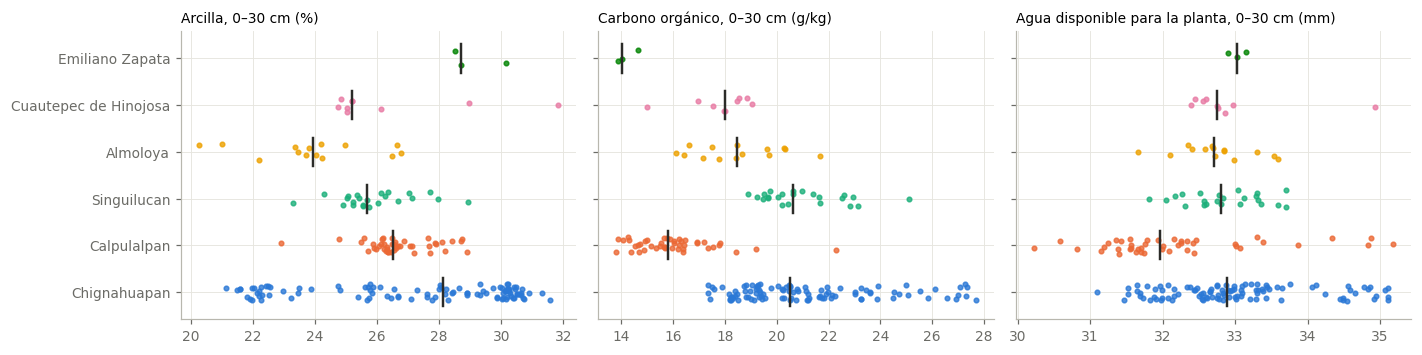

In [9]:
# 1.4 · Figura: suelo por municipio
top = attrs.Municipio.value_counts().index[:6].tolist()
t = SOIL.join(attrs.set_index("ID_POLIGONO").Municipio)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3), sharey=True)
for ax, (c, label) in zip(axes, [("soil_clay_0_30", "Arcilla, 0–30 cm (%)"), ("soil_soc_0_30", "Carbono orgánico, 0–30 cm (g/kg)"),
                                 ("soil_awc_mm_0_30", "Agua disponible para la planta, 0–30 cm (mm)")]):
    for k, mname in enumerate(top):
        v = t.loc[t.Municipio == mname, c].dropna()
        ax.scatter(v, np.full(len(v), k) + RNG.uniform(-0.18, 0.18, len(v)), s=9, color=MUNI_COLORS[k], alpha=0.8)
        if len(v):
            ax.plot([v.median()] * 2, [k - 0.3, k + 0.3], color=INK, lw=1.6)
    ax.set_yticks(range(len(top))); ax.set_yticklabels(top)
    ax.set_title(label, loc="left", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "nb05_soil_by_municipality.png", bbox_inches="tight"); plt.show()

## 2 · Paso B: armonizar y unir en la tabla maestra

Dos ajustes pequeños, decididos al revisar el reporte del cuaderno 04 y aplicados aquí para no tener que volver a correrlo:

1. **Pendiente cuando la mayor parte de la parcela cae en píxeles sin dato.** AGC_170 tiene píxeles de pendiente válidos solo en 2 % de su área y AGC_023 en 29 %. Un valor calculado con una franja de la parcela es menos confiable que la pendiente recalculada desde la elevación sobre toda la parcela (que coincide con la provista con r = 0.996). Regla: si menos de 50 % de la parcela es válida, se usa la pendiente recalculada.
2. **Dispersión dentro de una parcela que cabe en un solo píxel de terreno.** Una desviación estándar necesita al menos dos píxeles. Una parcela dentro de un solo píxel de 120 m no tiene dispersión medible → 0.

Después, todas las tablas se unen por `ID_POLIGONO`. La tabla maestra guarda los identificadores y las columnas de ubicación (municipio, estado, coordenadas, celda climática) *separadas* de las variables; los modelos deciden después cómo usar la ubicación.

In [10]:
# 2.1 · Armonizar y unir
sat = pd.read_parquet(FEATURES / "sat_features.parquet").set_index("ID_POLIGONO")
clim = pd.read_parquet(FEATURES / "climate_features.parquet").set_index("ID_POLIGONO")
topo = pd.read_parquet(FEATURES / "topo_features.parquet").set_index("ID_POLIGONO")
fix = topo.topo_slope_valid_share < 0.5
topo.loc[fix, "topo_slope_mean"] = topo.loc[fix, "topo_slope_dem_mean"]
topo.loc[fix, "topo_slope_std"] = np.nan
check("Pendiente tomada de la elevación donde < 50 % de la parcela tiene píxeles de pendiente válidos", True,
      f"{int(fix.sum())} parcela(s): {topo.index[fix].tolist()}", info=True)
one_px = topo.topo_elev_std.isna()
topo.loc[one_px, "topo_elev_std"] = 0.0
check("Dispersión de elevación igual a 0 en parcelas dentro de un solo píxel de terreno", True, f"{int(one_px.sum())} parcela(s): {topo.index[one_px].tolist()}", info=True)

FEAT = sat.join(clim).join(topo).join(SOIL)
id_cols = ["ID_POLIGONO", "Municipio", "Estado", "CONJUNTO", "is_train", "x_m", "y_m", "lon", "lat", "clim_cell"]
meta = attrs[[c for c in id_cols if c in attrs.columns]].set_index("ID_POLIGONO")
meta = meta.join(labels.set_index("ID_POLIGONO")[["RENDIMIENTO_T_HA"]])
MASTER = meta.join(FEAT, how="left")
assert len(MASTER) == 197 and MASTER.index.is_unique
assert MASTER.loc[~MASTER.is_train, "RENDIMIENTO_T_HA"].isna().all(), "las parcelas de predicción no deben tener rendimiento"
assert not any("rendimiento" in c.lower() for c in FEAT.columns)

cat = pd.concat([pd.read_csv(FEATURES / "feature_catalog.csv"), pd.read_csv(FEATURES / "feature_catalog_nb04.csv"),
                 pd.DataFrame(CATALOG)], ignore_index=True).drop_duplicates("feature", keep="last").set_index("feature")
cat = cat.reindex(FEAT.columns)
cat["use_in_model"] = cat.use_in_model.fillna(False).astype(bool)
cat["missing_%"] = (100 * FEAT.isna().mean()).round(2)
MODEL_FEATS = cat.index[cat.use_in_model].tolist()
miss = FEAT[MODEL_FEATS].isna().mean()
check("Tabla maestra: 197 parcelas, identificadores únicos, rendimiento solo en las de entrenamiento", True,
      f"{len(FEAT.columns)} variables ({len(MODEL_FEATS)} ofrecidas a los modelos) + {len(meta.columns)} columnas de identificación", info=True)
check("Variables del modelo: ≤ 5 % de faltantes cada una", bool((miss <= 0.05).all()),
      ", ".join(f"{k} {100 * v:.1f} %" for k, v in miss[miss > 0.05].items()) or f"máximo {100 * miss.max():.1f} %")
display(cat[cat.use_in_model].groupby("group").size().rename("model features").to_frame())

[INFO] Pendiente tomada de la elevación donde < 50 % de la parcela tiene píxeles de pendiente válidos — 2 parcela(s): ['AGC_023', 'AGC_170']
[INFO] Dispersión de elevación igual a 0 en parcelas dentro de un solo píxel de terreno — 1 parcela(s): ['AGC_091']
[INFO] Tabla maestra: 197 parcelas, identificadores únicos, rendimiento solo en las de entrenamiento — 278 variables (268 ofrecidas a los modelos) + 10 columnas de identificación
[PASS] Variables del modelo: ≤ 5 % de faltantes cada una — máximo 1.5 %
                 model features
group                          
climate                      48
climate anomaly              18
history                       8
phenology                    44
plot                          1
soil                         21
terrain                       9
uniformity                    4
window                      115


## 3 · Paso C: los pliegues fijos de validación

**Esquema principal: 10 repeticiones de validación cruzada estratificada de 5 pliegues.** Las 138 parcelas de entrenamiento se dividen en 5 grupos; cada modelo se entrena con 4 y se evalúa en el 5.º, cinco veces, así que cada parcela se evalúa una vez sin haber sido vista. Esto se repite 10 veces con particiones aleatorias distintas, lo que da 50 métricas cuya dispersión indica qué parte de una diferencia entre dos modelos es suerte.
*Estratificada* significa que cada pliegue recibe una mezcla similar de municipios y de rendimientos bajos, medios y altos. Los municipios con menos de 10 parcelas de entrenamiento se agrupan como «otros» para que cada estrato tenga al menos 5 parcelas.

**Por qué los pliegues aleatorios son la prueba principal correcta aquí.** Las 59 parcelas de predicción están intercaladas con las de entrenamiento (mediana de 0.35 km a la parcela de entrenamiento más cercana). Un buen esquema de validación debe reproducir esa situación. Abajo lo verificamos: en los pliegues aleatorios, la distancia de cada parcela apartada a su parcela de entrenamiento más cercana debería parecerse a la distancia real de las parcelas de predicción a las de entrenamiento.

**Esquema secundario: bloques espaciales.** Las parcelas de entrenamiento se agrupan en 10 conglomerados geográficos (k-medias sobre las coordenadas) y se apartan conglomerados completos. Es más difícil, porque las parcelas apartadas no tienen vecinas cercanas en entrenamiento, y mide qué tan bien funcionaría un modelo en zonas *nuevas*. Lo reportamos por transparencia y robustez; la situación del reto corresponde al esquema principal.

In [11]:
# 3.1 · Construir y guardar los pliegues
from sklearn.model_selection import RepeatedStratifiedKFold, GroupKFold
from sklearn.cluster import KMeans

TR = MASTER[MASTER.is_train].copy()
tr_ids = TR.index.to_numpy()
y = TR.RENDIMIENTO_T_HA.to_numpy()
muni_n = TR.Municipio.value_counts()
muni_grp = TR.Municipio.where(TR.Municipio.map(muni_n) >= 10, "other")
terc = pd.qcut(TR.RENDIMIENTO_T_HA.rank(method="first"), 3, labels=["low", "mid", "high"]).astype(str)
strata = muni_grp + "_" + terc
small = strata.map(strata.value_counts()) < 5
strata[small] = muni_grp[small]
strata[strata.map(strata.value_counts()) < 5] = "other"
display(strata.value_counts().rename("plots").to_frame().T)
check("Cada estrato tiene ≥ 5 parcelas", bool(strata.value_counts().min() >= 5), f"estrato más pequeño: {strata.value_counts().min()} parcelas")

rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
folds = []
for k, (tr_i, te_i) in enumerate(rskf.split(tr_ids, strata)):
    folds.append({"repeat": k // 5, "fold": k % 5, "test": tr_ids[te_i].tolist()})
(MODELS / "cv_folds.json").write_text(json.dumps({"scheme": "10 x repeated stratified 5-fold", "seed": SEED,
                                                  "strata": strata.to_dict(), "folds": folds}, indent=1))

XY = TR[["x_m", "y_m"]].to_numpy()
blocks = KMeans(n_clusters=10, n_init=20, random_state=SEED).fit_predict(XY)
sp_folds = []
for k, (tr_i, te_i) in enumerate(GroupKFold(n_splits=5).split(tr_ids, y, groups=blocks)):
    sp_folds.append({"fold": k, "test": tr_ids[te_i].tolist()})
(MODELS / "cv_spatial.json").write_text(json.dumps({"scheme": "spatial blocks: k-means (10 clusters) on coordinates, GroupKFold(5)",
                                                    "seed": SEED, "block": dict(zip(tr_ids.tolist(), blocks.tolist())),
                                                    "folds": sp_folds}, indent=1))
sizes = pd.DataFrame({"random (repeat 0)": [len(f["test"]) for f in folds[:5]], "spatial": [len(f["test"]) for f in sp_folds]},
                     index=[f"fold {i}" for i in range(5)])
display(sizes.T)

       Chignahuapan_high  Chignahuapan_mid  Calpulalpan_low  other  Singuilucan_low  Almoloya_mid  Almoloya_high  Calpulalpan_mid
plots                 38                30               25     16               14             5              5                5
[PASS] Cada estrato tiene ≥ 5 parcelas — estrato más pequeño: 5 parcelas
                   fold 0  fold 1  fold 2  fold 3  fold 4
random (repeat 0)      28      28      28      27      27
spatial                37      26      24      24      27


                                     50%   75%    max
real: prediction → training         0.35  0.56   1.91
random folds: held-out → training   0.41  0.79  10.51
spatial folds: held-out → training  2.83  5.04  13.71
[PASS] Los pliegues aleatorios reproducen las distancias reales de predicción (mediana dentro de ±50 %) — mediana en km: real 0.35, pliegues aleatorios 0.41, pliegues espaciales 2.83


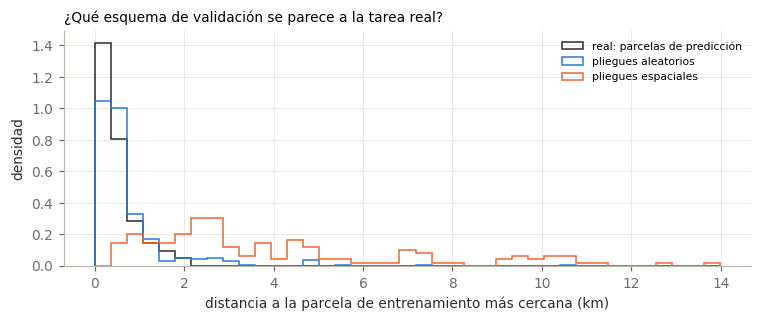

In [12]:
# 3.2 · ¿El esquema principal imita la tarea real de predicción? Distancia a la parcela de entrenamiento más cercana
def nn_dist_km(test_ids, train_ids):
    A = MASTER.loc[test_ids, ["x_m", "y_m"]].to_numpy()
    B = MASTER.loc[train_ids, ["x_m", "y_m"]].to_numpy()
    return np.sqrt(((A[:, None] - B[None]) ** 2).sum(-1)).min(1) / 1000

real = nn_dist_km(MASTER.index[~MASTER.is_train], tr_ids)
rand = np.concatenate([nn_dist_km(f["test"], np.setdiff1d(tr_ids, f["test"])) for f in folds])
spat = np.concatenate([nn_dist_km(f["test"], np.setdiff1d(tr_ids, f["test"])) for f in sp_folds])
dist_tab = pd.DataFrame({"real: prediction → training": pd.Series(real).describe(),
                         "random folds: held-out → training": pd.Series(rand).describe(),
                         "spatial folds: held-out → training": pd.Series(spat).describe()}).T[["50%", "75%", "max"]].round(2)
display(dist_tab)
check("Los pliegues aleatorios reproducen las distancias reales de predicción (mediana dentro de ±50 %)",
      abs(np.median(rand) / np.median(real) - 1) <= 0.5,
      f"mediana en km: real {np.median(real):.2f}, pliegues aleatorios {np.median(rand):.2f}, pliegues espaciales {np.median(spat):.2f}")
fig, ax = plt.subplots(figsize=(7, 3))
bins = np.linspace(0, max(spat.max(), real.max()) * 1.02, 40)
for v, lab, col in [(real, "real: parcelas de predicción", INK), (rand, "pliegues aleatorios", "#2a78d6"), (spat, "pliegues espaciales", "#eb6834")]:
    ax.hist(v, bins=bins, density=True, histtype="step", lw=1.6, color=col, label=lab)
ax.set_xlabel("distancia a la parcela de entrenamiento más cercana (km)"); ax.set_ylabel("densidad")
ax.set_title("¿Qué esquema de validación se parece a la tarea real?", loc="left", fontsize=9); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "nb05_fold_distances.png", bbox_inches="tight"); plt.show()

## 4 · Paso D: las referencias oficiales (la métrica a superar)

Tres modelos que usan **solo la ubicación**, evaluados en los pliegues fijos:
- **media general**: predice para cada parcela el rendimiento promedio de la parte de entrenamiento;
- **media municipal**: el promedio de las parcelas de entrenamiento del mismo municipio (media general si el municipio no aparece en la parte de entrenamiento);
- **k vecinos más cercanos**: el rendimiento promedio de las *k* parcelas de entrenamiento más cercanas, con *k* elegido *dentro* de cada parte de entrenamiento (dejando una fuera, de 1 a 30), así que las parcelas apartadas nunca influyen en *k*.

El RMSE y el MAE se promedian sobre los pliegues. **El R² se calcula con todas las predicciones fuera de pliegue juntas** (un valor por repetición, luego promediado): el R² dentro de un solo pliegue pequeño, sobre todo en un bloque espacial cuyas parcelas se parecen entre sí, puede salir negativo incluso con un modelo razonable, así que el R² por pliegue no tiene sentido.

El **error estándar (EE)** es la dispersión de las 50 métricas por pliegue dividida entre √50; en términos generales, una diferencia entre dos modelos menor a ~2 EE no es convincente. Estas cifras reemplazan la referencia optimista del cuaderno 01 (dejando una fuera) y son el umbral para los cuadernos 06 y 07.

In [13]:
# 4.1 · Referencias en ambos esquemas
def metrics(yt, yp):
    e = yt - yp
    return {"rmse": float(np.sqrt(np.mean(e ** 2))), "mae": float(np.mean(np.abs(e))),
            "r2": float(1 - np.sum(e ** 2) / np.sum((yt - yt.mean()) ** 2)) if len(yt) > 1 else np.nan}

def knn_pred(train_ids, test_ids, k_max=30):
    Xtr = MASTER.loc[train_ids, ["x_m", "y_m"]].to_numpy(); ytr = MASTER.loc[train_ids, "RENDIMIENTO_T_HA"].to_numpy()
    D = np.sqrt(((Xtr[:, None] - Xtr[None]) ** 2).sum(-1)); np.fill_diagonal(D, np.inf)
    order = np.argsort(D, 1)
    rmse = [np.sqrt(np.mean((ytr - ytr[order[:, :k]].mean(1)) ** 2)) for k in range(1, k_max + 1)]
    k = int(np.argmin(rmse)) + 1
    Xte = MASTER.loc[test_ids, ["x_m", "y_m"]].to_numpy()
    Dt = np.sqrt(((Xte[:, None] - Xtr[None]) ** 2).sum(-1))
    return ytr[np.argsort(Dt, 1)[:, :k]].mean(1), k

def evaluate(fold_list):
    rows, ks, oof = [], [], []
    for f in fold_list:
        te = np.array(f["test"]); trn = np.setdiff1d(tr_ids, te)
        yt = MASTER.loc[te, "RENDIMIENTO_T_HA"].to_numpy()
        ytr = MASTER.loc[trn, "RENDIMIENTO_T_HA"]
        gm = np.full(len(te), ytr.mean())
        mm = MASTER.loc[trn].groupby("Municipio").RENDIMIENTO_T_HA.mean()
        mu = MASTER.loc[te, "Municipio"].map(mm).fillna(ytr.mean()).to_numpy()
        kn, k = knn_pred(trn, te)
        ks.append(k)
        for name, p in [("global mean", gm), ("municipality mean", mu), ("k nearest neighbours", kn)]:
            rows.append({"model": name, **metrics(yt, p)})
            oof.append(pd.DataFrame({"model": name, "repeat": f.get("repeat", 0), "y": yt, "p": p}))
    r = pd.DataFrame(rows)
    out = r.groupby("model").agg(rmse=("rmse", "mean"), rmse_se=("rmse", lambda s: s.std(ddof=1) / np.sqrt(len(s))),
                                 mae=("mae", "mean"))
    o = pd.concat(oof)
    out["r2_pooled"] = o.groupby(["model", "repeat"]).apply(lambda g: metrics(g.y.to_numpy(), g.p.to_numpy())["r2"]).groupby("model").mean()
    return out.sort_values("rmse"), ks

BASE_RAND, ks_r = evaluate(folds)
BASE_SPAT, ks_s = evaluate(sp_folds)
print("Esquema principal (10 × 5 pliegues):"); display(BASE_RAND.round(3))
print("Bloques espaciales:"); display(BASE_SPAT.round(3))
best = BASE_RAND.index[0]
check("Referencia oficial a superar (esquema principal)", True,
      f"{best}: RMSE {BASE_RAND.loc[best, 'rmse']:.3f} ± {BASE_RAND.loc[best, 'rmse_se']:.3f} t/ha, "
      f"R² agrupado {BASE_RAND.loc[best, 'r2_pooled']:.3f}; k elegido dentro de los pliegues: mediana {int(np.median(ks_r))}", info=True)
check("Referencia en bloques espaciales (más difícil, zonas nuevas)", True,
      f"{BASE_SPAT.index[0]}: RMSE {BASE_SPAT.iloc[0]['rmse']:.3f} t/ha", info=True)
(MODELS / "baselines_cv.json").write_text(json.dumps({"main": BASE_RAND.round(4).to_dict("index"),
                                                      "spatial": BASE_SPAT.round(4).to_dict("index"),
                                                      "k_main_median": int(np.median(ks_r))}, indent=1))

/tmp/ipykernel_2373/2167580476.py:35: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  out["r2_pooled"] = o.groupby(["model", "repeat"]).apply(lambda g: metrics(g.y.to_numpy(), g.p.to_numpy())["r2"]).groupby("model").mean()
/tmp/ipykernel_2373/2167580476.py:35: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  out["r2_pooled"] = o.groupby(["model", "repeat"]).apply(lambda g: metrics(g.y.to_numpy(), g.p.to_numpy())

Esquema principal (10 × 5 pliegues):
                       rmse  rmse_se    mae  r2_pooled
model                                                 
municipality mean     0.498    0.015  0.331      0.640
k nearest neighbours  0.528    0.013  0.384      0.600
global mean           0.848    0.008  0.750     -0.004
Bloques espaciales:
                       rmse  rmse_se    mae  r2_pooled
model                                                 
k nearest neighbours  0.635    0.112  0.470      0.364
municipality mean     0.635    0.078  0.457      0.400
global mean           0.995    0.082  0.920     -0.367
[INFO] Referencia oficial a superar (esquema principal) — municipality mean: RMSE 0.498 ± 0.015 t/ha, R² agrupado 0.640; k elegido dentro de los pliegues: mediana 11
[INFO] Referencia en bloques espaciales (más difícil, zonas nuevas) — k nearest neighbours: RMSE 0.635 t/ha


722

## 5 · Paso E: ¿qué variables dicen lo mismo? (sin usar el rendimiento)

Muchas variables son casi copias unas de otras: las fechas fenológicas de Planet y de Sentinel-2 coinciden con pocos días de diferencia, y la temperatura media y los grados-día de una misma ventana se mueven juntos. Los casi duplicados vuelven inestables a los modelos y engañosos los ordenamientos de importancia (el mérito se reparte entre gemelas).

Calculamos la correlación de Spearman entre cada par de variables del modelo **en las 197 parcelas** (no usa el rendimiento, así que incluir las parcelas de predicción es legítimo) y agrupamos las variables con un conglomerado jerárquico: las variables de un mismo grupo se correlacionan con |ρ| ≥ 0.9. El identificador del grupo se guarda en el catálogo; los cuadernos 06 y 07 conservan una representante por grupo *dentro de cada pliegue de entrenamiento*.

In [14]:
# 5.1 · Grupos de redundancia
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
X = FEAT[MODEL_FEATS].astype(float)
X = X.loc[:, X.nunique() > 1]
R = X.rank().corr().abs().fillna(0).to_numpy().copy()
np.fill_diagonal(R, 1)
Z = linkage(squareform(1 - R, checks=False), method="average")
cl = fcluster(Z, t=0.10, criterion="distance")
clusters = pd.Series(cl, index=X.columns, name="redundancy_cluster")
cat["redundancy_cluster"] = clusters.reindex(cat.index)
sizes_c = clusters.value_counts()
check("Mapa de redundancia (agrupadas con |ρ| ≥ 0.9)", True,
      f"{X.shape[1]} variables del modelo → {clusters.nunique()} grupos; {int((sizes_c > 1).sum())} grupos con casi duplicados; "
      f"el más grande tiene {sizes_c.max()} variables", info=True)
ex = clusters[clusters == sizes_c.index[0]].index.tolist()
print("Grupo más grande:", ex[:12], "…" if len(ex) > 12 else "")
cat.to_csv(FEATURES / "feature_catalog_all.csv")
MASTER.reset_index().to_parquet(FEATURES / "master.parquet", index=False)
print("guardados master.parquet y feature_catalog_all.csv")

[INFO] Mapa de redundancia (agrupadas con |ρ| ≥ 0.9) — 268 variables del modelo → 142 grupos; 60 grupos con casi duplicados; el más grande tiene 16 variables
Grupo más grande: ['s2_ndvi_peak', 'pl_evi_mid_mean', 'pl_msavi_mid_mean', 'pl_evi_season_max', 'pl_msavi_season_max', 's2_ndvi_mid_mean', 's2_evi_mid_mean', 's2_mra_mid_mean', 's2_lai_mid_mean', 's2_fapar_mid_mean', 's2_savi_mid_mean', 's2_ndvi_season_max'] …
guardados master.parquet y feature_catalog_all.csv


## 6 · Paso F: mirada descriptiva a todos los grupos de variables, fuentes y reporte

Como antes, **solo descriptivo** (parcelas de entrenamiento; aquí no se selecciona nada). ρ de Spearman dentro de municipio, las 25 primeras entre variables satelitales, climáticas, de terreno y de suelo, coloreadas por grupo. |ρ| ≈ 0.17 es aproximadamente el umbral de significancia con 138 parcelas.

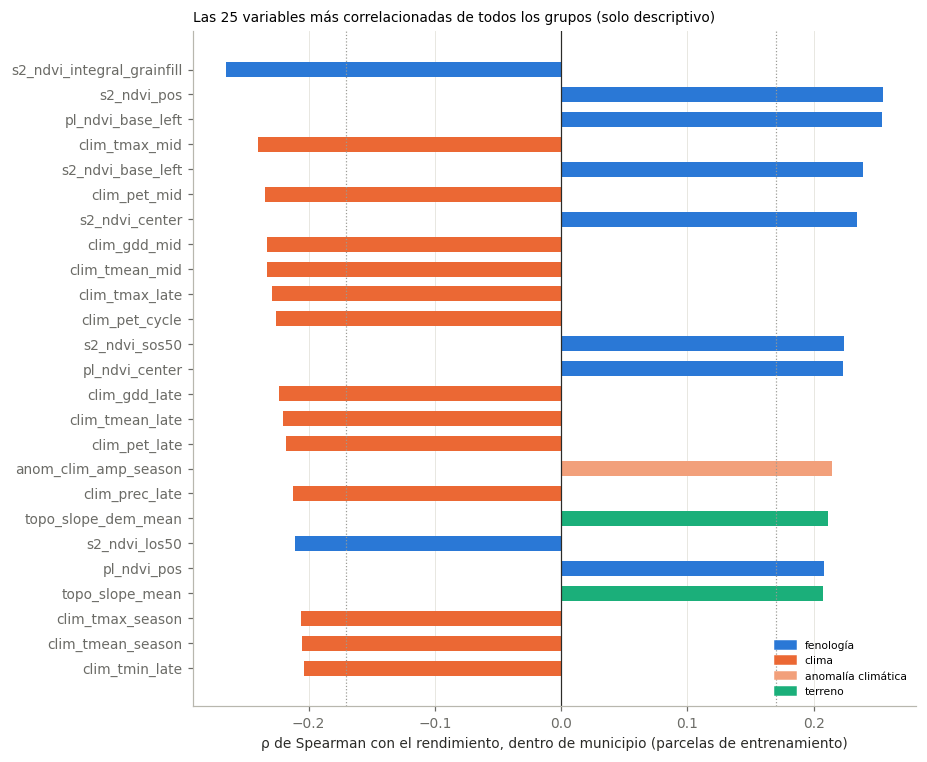

[INFO] Descriptivo: variables de suelo más fuertes dentro de municipio — soil_bdod_0_5 ρ = -0.20; soil_soc_0_30 ρ = +0.20; soil_sand_0_30 ρ = +0.18


In [15]:
# 6.1 · Correlaciones descriptivas
trm = MASTER[MASTER.is_train]
num = [c for c in MODEL_FEATS if FEAT[c].nunique() > 2]
overall = trm[num].corrwith(trm.RENDIMIENTO_T_HA, method="spearman")
dm = trm[num + ["RENDIMIENTO_T_HA"]].sub(trm.groupby("Municipio")[num + ["RENDIMIENTO_T_HA"]].transform("mean"))
within = dm[num].corrwith(dm.RENDIMIENTO_T_HA, method="spearman")
look = pd.DataFrame({"overall": overall, "within_municipality": within}).join(cat[["group", "sensor", "redundancy_cluster"]])
look = look.reindex(look.within_municipality.abs().sort_values(ascending=False).index)
look.to_csv(QA / "nb05_descriptive_correlations.csv")
t25 = look.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 7))
ax.barh(t25.index, t25.within_municipality, color=[GROUP_COLORS.get(g, GREY) for g in t25.group], height=0.6)
ax.axvline(0, color=INK, lw=0.8)
for xv in (-0.17, 0.17):
    ax.axvline(xv, color=GREY, lw=0.8, ls=":")
ax.grid(axis="y", visible=False)
ax.set_xlabel("ρ de Spearman con el rendimiento, dentro de municipio (parcelas de entrenamiento)")
ax.set_title("Las 25 variables más correlacionadas de todos los grupos (solo descriptivo)", loc="left", fontsize=9)
present = [g for g in GROUP_COLORS if g in set(t25.group)]
ax.legend(handles=[matplotlib.patches.Patch(color=GROUP_COLORS[g], label=GRUPOS.get(g, g)) for g in present], fontsize=7, loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "nb05_descriptive_correlations.png", bbox_inches="tight"); plt.show()
soil_top = look[look.group == "soil"].head(3)
check("Descriptivo: variables de suelo más fuertes dentro de municipio", True,
      "; ".join(f"{i} ρ = {r.within_municipality:+.2f}" for i, r in soil_top.iterrows()), info=True)

In [16]:
# 6.2 · docs/sources.md (datos y métodos: las bases piden documentar cada fuente)
sources = f"""# Fuentes de datos y referencias de métodos — Reto AgroCebada 2026
Actualizado {datetime.now():%Y-%m-%d}

## Datos proporcionados por el reto
- Polígonos de las parcelas, área, rendimiento (t/ha, ciclo abril–octubre 2025) y CONJUNTO — Reto AgroCebada FIRA 2026.
- Índices de Sentinel-2 y Landsat 2022–2025 (conjunto Básico); índices de Planet 2025 (conjunto PRO) — Reto AgroCebada FIRA 2026.
- Precipitación mensual CHIRPS: Funk, C. et al. (2015). The climate hazards infrared precipitation with stations — a new environmental record for monitoring extremes. Scientific Data 2, 150066. https://doi.org/10.1038/sdata.2015.66
- Tmín/Tmáx mensual CHIRTS-ERA5: Climate Hazards Center (2025). CHIRTS-ERA5 Data Repository. UC Santa Barbara. https://doi.org/10.15780/G2F08J
- Elevación y pendiente: INEGI (2025). Continuo de Elevaciones Mexicano 4.0 (CEM 4.0). Aguascalientes, México.

## Datos públicos añadidos por el equipo
- SoilGrids 2.0 (ISRIC), 250 m, propiedades {', '.join(SOIL_PROPS)}; profundidades {', '.join(DEPTHS)}; descargado el {datetime.now():%Y-%m-%d} de {WCS_URL.format(prop='<propiedad>')} ({SOIL_METHOD}).
  Poggio, L. et al. (2021). SoilGrids 2.0: producing soil information for the globe with quantified spatial uncertainty. SOIL 7, 217–240. https://doi.org/10.5194/soil-7-217-2021

## Métodos
- Suavizador de Whittaker: Eilers, P. H. C. (2003). A perfect smoother. Analytical Chemistry 75(14), 3631–3636.
- Reponderación iterativa robusta para series de tiempo: Garcia, D. (2010). Robust smoothing of gridded data in one and higher dimensions with missing values. Computational Statistics & Data Analysis 54(4), 1167–1178.
- Fenología por umbral de amplitud (TIMESAT): Jönsson, P. y Eklundh, L. (2004). TIMESAT — a program for analyzing time-series of satellite sensor data. Computers & Geosciences 30, 833–845.
- Evapotranspiración de Hargreaves–Samani y radiación extraterrestre: Allen, R. G., Pereira, L. S., Raes, D. y Smith, M. (1998). Crop evapotranspiration. FAO Irrigation and Drainage Paper 56 (ecs. 21 y 52).
- Retención de agua en el suelo: Saxton, K. E. y Rawls, W. J. (2006). Soil water characteristic estimates by texture and organic matter for hydrologic solutions. Soil Science Society of America Journal 70, 1569–1578.
- Recorte de polígonos: Sutherland, I. E. y Hodgman, G. W. (1974). Reentrant polygon clipping. Communications of the ACM 17(1), 32–42.
"""
(DOCS / "sources.md").write_text(sources, encoding="utf-8")
print(f"escrito {DOCS / 'sources.md'}")

escrito /content/drive/MyDrive/AgroCebada/docs/sources.md


In [ ]:
# 6.3 · Reporte
def md_table(df):
    df = df.copy()
    cols = [str(c) for c in df.columns]
    out = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        out.append("| " + " | ".join("" if pd.isna(v) else (f"{v:.4g}" if isinstance(v, float) else str(v)) for v in r.values) + " |")
    return "\n".join(out)

chk = pd.DataFrame(CHECKS)
lines = ["# Reporte del cuaderno 05: suelos, tabla maestra, pliegues y referencias",
         f"Generado {datetime.now():%Y-%m-%d %H:%M} · Colab: {IN_COLAB}", "",
         f"**Conteo de estados:** {chk.status.value_counts().to_dict()}", "",
         "## Verificaciones", md_table(chk), "",
         "## Suelo (0–30 cm)", md_table(ranges.round(2)), "",
         "## Variables del modelo por grupo", md_table(cat[cat.use_in_model].groupby("group").size().rename("n").reset_index()), "",
         "## Distancia a la parcela de entrenamiento más cercana (km)", md_table(dist_tab.reset_index()), "",
         "## Referencias oficiales: esquema principal (10 repeticiones de 5 pliegues estratificados)", md_table(BASE_RAND.round(4).reset_index()), "",
         "## Referencias: bloques espaciales", md_table(BASE_SPAT.round(4).reset_index()), "",
         "## Correlaciones descriptivas con el rendimiento (parcelas de entrenamiento; 25 primeras por |ρ| dentro de municipio)",
         md_table(look.head(25).round(3).reset_index().rename(columns={"index": "feature"}))]
(QA / "nb05_report.md").write_text("\n".join(lines), encoding="utf-8")
print(chk.status.value_counts().to_dict())
problems = chk[chk.status.isin(["WARN", "FAIL"])]
display(problems if len(problems) else "Todas las verificaciones pasaron.")
print(f"Reporte: {QA / 'nb05_report.md'}")

## Resultado y siguiente paso

1. **`qa/figures/nb05_fold_distances.png`**: la curva azul (pliegues aleatorios) debe quedar cerca de la negra (parcelas de predicción reales): es la evidencia de que el esquema principal de validación imita la tarea real. La curva naranja (bloques espaciales) es la prueba más difícil de «zona nueva».
2. **`qa/figures/nb05_soil_by_municipality.png`**: diferencias de suelo entre municipios y dentro de ellos.
3. **`qa/nb05_report.md`**: la referencia oficial que contiene es la cifra que todo modelo debe superar a partir de aquí.
4. Sigue el **cuaderno 06**: la escalera de modelos (ridge, bosque aleatorio, LightGBM, procesos gaussianos espaciales y el PG jerárquico propio), todos evaluados en estos pliegues, con selección de variables y ajuste *dentro* de cada pliegue.